In [1]:
#Import library
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import pairwise_distances
from sklearn.decomposition import PCA

In [2]:
from pathlib import Path

def data_path(name):
    """Resolve a file in the project's data/ directory from any depth."""
    d = Path.cwd()
    for _ in range(5):
        if (d / "data" / name).exists():
            return d / "data" / name
        d = d.parent
    raise FileNotFoundError(f"data/{name} not found above {Path.cwd()}")

#Upload file excel
filedata = data_path("penguins.csv")
readexcel = pd.read_csv(filedata)
df= pd.DataFrame(readexcel)
df.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE


In [3]:
#Preprocessing
#Drop data null
df_clean = df.dropna()
#Encoding sex (male:1 female: 0)
le = LabelEncoder()
df_clean['sex'] = le.fit_transform(df_clean['sex'])
#Standarisasi
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_clean)
#PCA
pca = PCA(n_components=2)
df_pca = pca.fit_transform(df_scaled)

<tmp>\ipykernel_19176\718682733.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['sex'] = le.fit_transform(df_clean['sex'])


In [4]:
#Diana
def diana_like_clustering(X, n_clusters):
    clusters = [X]
    
    while len(clusters) < n_clusters:
        largest_cluster_idx = np.argmax([len(cluster) for cluster in clusters])
        largest_cluster = clusters.pop(largest_cluster_idx)
        distance_matrix = pairwise_distances(largest_cluster)
        idx_max_dist = np.unravel_index(np.argmax(distance_matrix), distance_matrix.shape)
        point1, point2 = largest_cluster[idx_max_dist[0]], largest_cluster[idx_max_dist[1]]
        cluster1, cluster2 = [], []
        for point in largest_cluster:
            if np.linalg.norm(point - point1) < np.linalg.norm(point - point2):
                cluster1.append(point)
            else:
                cluster2.append(point)
        
        clusters.append(np.array(cluster1))
        clusters.append(np.array(cluster2))
    
    return clusters
clusters = diana_like_clustering(df_pca, n_clusters=3)

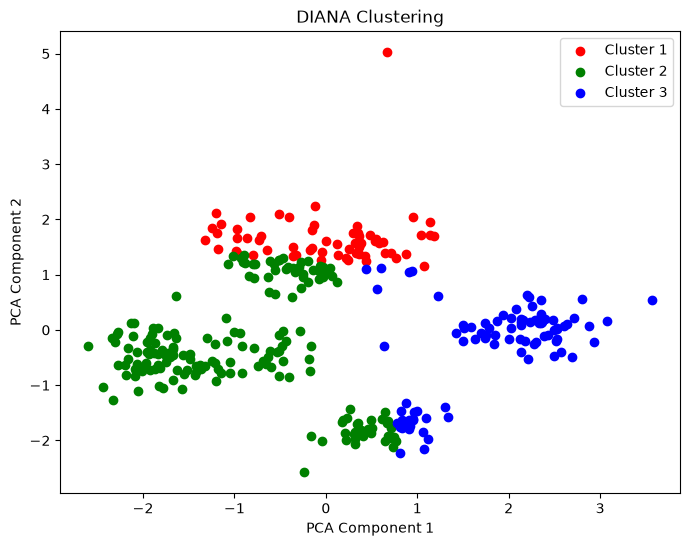

In [5]:
#Visualisasi
colors = ['r', 'g', 'b']
plt.figure(figsize=(8, 6))
for idx, cluster in enumerate(clusters):
    plt.scatter(cluster[:, 0], cluster[:, 1], color=colors[idx], label=f'Cluster {idx+1}')
plt.title('DIANA Clustering')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend()
plt.show()